# ICS1512 — Machine Learning Algorithms Laboratory
**Sri Sivasubramaniya Nadar College of Engineering, Chennai** (An Autonomous Institution Affiliated to Anna University)

| | |
|---|---|
| **Experiment No.** | 5 |
| **Experiment Title** | Decision Tree and Random Forest: A Comparative Classification Study |
| **Student Name** | Emmanuel Maximus Ravichandran |
| **Register Number** | 3122247001015 |
| **Faculty** | Dr. Poreddy Ajay Kumar Reddy |
| **Submission Date** | |

# Objective



- To implement a Decision Tree classifier.
- To extend the Decision Tree into a Random Forest ensemble model.
- To study the impact of hyperparameters on overfitting and generalisation.
- To select optimal hyperparameters using 5-fold cross-validation.
- To compare single-tree and ensemble-tree models.

# Problem Statement



Given 30 numerical measurements computed from a digitised image of a fine-needle aspirate of
a breast mass, classify the tumour as malignant (M) or benign (B). The task is supervised
binary classification in which a missed malignant case (false negative) is more costly than
a false alarm, so recall for the malignant class is monitored alongside accuracy, precision,
F1-score and ROC-AUC. A single Decision Tree is compared with a Random Forest after both are
tuned by 5-fold cross-validation.

# Dataset Description




| Dataset Name | Wisconsin Diagnostic Breast Cancer (WDBC) |
|---|---|
| Dataset Source | UCI Machine Learning Repository (`data/wdbc.data`) |
| Number of Samples | 569 |
| Number of Features | 30 (mean, standard error and worst value of 10 cell-nucleus measurements) |
| Target | Diagnosis: M = malignant (212), B = benign (357) |
| Missing Values | 0 |
| Train-Test Split | 80 / 20, stratified (455 train / 114 test) |

# Theory

## Decision Tree



A Decision Tree recursively splits the feature space with axis-aligned thresholds so that
each child node is purer than its parent. Node impurity is measured by the Gini index or the
entropy,

\[ \mathrm{Gini}(t) = 1 - \sum_{k} p_k^{2}, \qquad \mathrm{Entropy}(t) = -\sum_{k} p_k \log_2 p_k , \]

where p_k is the fraction of class k in node t. The split that gives the largest impurity
decrease is chosen. An unrestricted tree can keep splitting until every leaf is pure, which
memorises noise (high variance, overfitting). The depth (max_depth), the minimum samples
needed to split (min_samples_split) and the minimum samples per leaf (min_samples_leaf)
limit this.

## Random Forest



A Random Forest trains many trees on bootstrap samples of the training data (bagging). At
every split each tree considers only a random subset of the features (max_features, e.g.
sqrt or log2 of the number of features), which decorrelates the trees. The prediction is the
majority vote of the trees. Averaging decorrelated high-variance trees lowers the variance
of the ensemble while keeping the low bias of deep trees.

# Setup and Data Preparation

## Setup and Imports




A hidden setup block defines two small helpers that appear at the end of the figure and
table cells below: _fig() closes the Matplotlib figure and returns its caption and image
link to Org, and _tbl() turns a DataFrame into a captioned Org table, so that figures and
tables regenerate with the report each time the file is executed.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix,
                             roc_curve, auc)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
os.makedirs("figures", exist_ok=True)
sns.set_style("whitegrid")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)
print("setup complete")

setup complete


## Step 1: Load the Dataset and Encode Class Labels

In [2]:
base = ["radius", "texture", "perimeter", "area", "smoothness", "compactness", "concavity",
        "concave points", "symmetry", "fractal dimension"]
feature_names = [f"mean {b}" for b in base] + [f"{b} error" for b in base] + [f"worst {b}" for b in base]
df = pd.read_csv("data/wdbc.data", header=None, names=["id", "diagnosis"] + feature_names)
df["target"] = (df["diagnosis"] == "M").astype(int)
print("Shape:", df.shape)
print("Class encoding -> 1: Malignant (M), 0: Benign (B)")
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate patient IDs:", int(df["id"].duplicated().sum()))
print(df[["diagnosis", "target"] + feature_names[:4]].head())

Shape: (569, 33)
Class encoding -> 1: Malignant (M), 0: Benign (B)
Missing values: 0
Duplicate patient IDs: 0
  diagnosis  target  mean radius  mean texture  mean perimeter  mean area
0         M       1        17.99         10.38          122.80     1001.0
1         M       1        20.57         17.77          132.90     1326.0
2         M       1        19.69         21.25          130.00     1203.0
3         M       1        11.42         20.38           77.58      386.1
4         M       1        20.29         14.34          135.10     1297.0


**Inference:** The WDBC file has 569 patients, 30 numeric features (mean, standard error and worst value of
ten nucleus measurements), an ID and the diagnosis. There are no missing values and no
duplicate IDs. The features are on very different scales (mean area averages 655 with a
standard deviation of 352, whereas mean fractal dimension averages 0.063 with a standard
deviation of 0.007). Tree-based models split on thresholds and are not affected by monotone
rescaling, so no feature scaling is applied in this experiment, unlike the logistic
regression and SVM experiment. Malignant is encoded as 1 so that precision and recall refer
to detecting cancer.

In [3]:
print(df[feature_names].describe().T[["mean", "std", "min", "max"]].round(3).head(10))

                           mean      std      min       max
mean radius              14.127    3.524    6.981    28.110
mean texture             19.290    4.301    9.710    39.280
mean perimeter           91.969   24.299   43.790   188.500
mean area               654.889  351.914  143.500  2501.000
mean smoothness           0.096    0.014    0.053     0.163
mean compactness          0.104    0.053    0.019     0.345
mean concavity            0.089    0.080    0.000     0.427
mean concave points       0.049    0.039    0.000     0.201
mean symmetry             0.181    0.027    0.106     0.304
mean fractal dimension    0.063    0.007    0.050     0.097


# Step 2: Exploratory Data Analysis

In [4]:
print(df["diagnosis"].value_counts())
print((df["diagnosis"].value_counts(normalize=True) * 100).round(1))

diagnosis
B    357
M    212
Name: count, dtype: int64
diagnosis
B    62.7
M    37.3
Name: proportion, dtype: float64


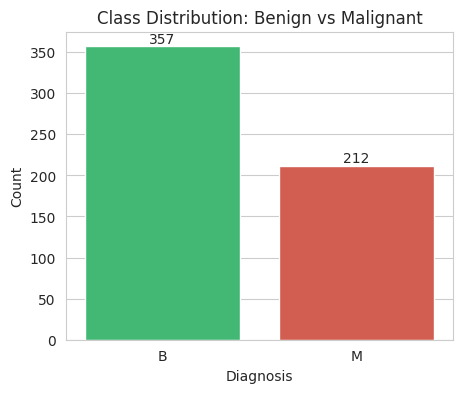

In [5]:
plt.figure(figsize=(5, 4))
ax = sns.countplot(data=df, x="diagnosis", order=["B", "M"], palette=["#2ecc71", "#e74c3c"])
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height() + 4), ha="center")
plt.title("Class Distribution: Benign vs Malignant")
plt.xlabel("Diagnosis"); plt.ylabel("Count")
plt.savefig("figures/fig_01_class_distribution.png", dpi=110, bbox_inches="tight")
plt.show()

**Inference:** The data contains 357 benign (62.7%) and 212 malignant (37.3%) cases. The imbalance is
moderate, so stratified splitting is used everywhere to keep the class proportions the same
in every split and fold, and recall on the malignant class is reported in addition to
accuracy.

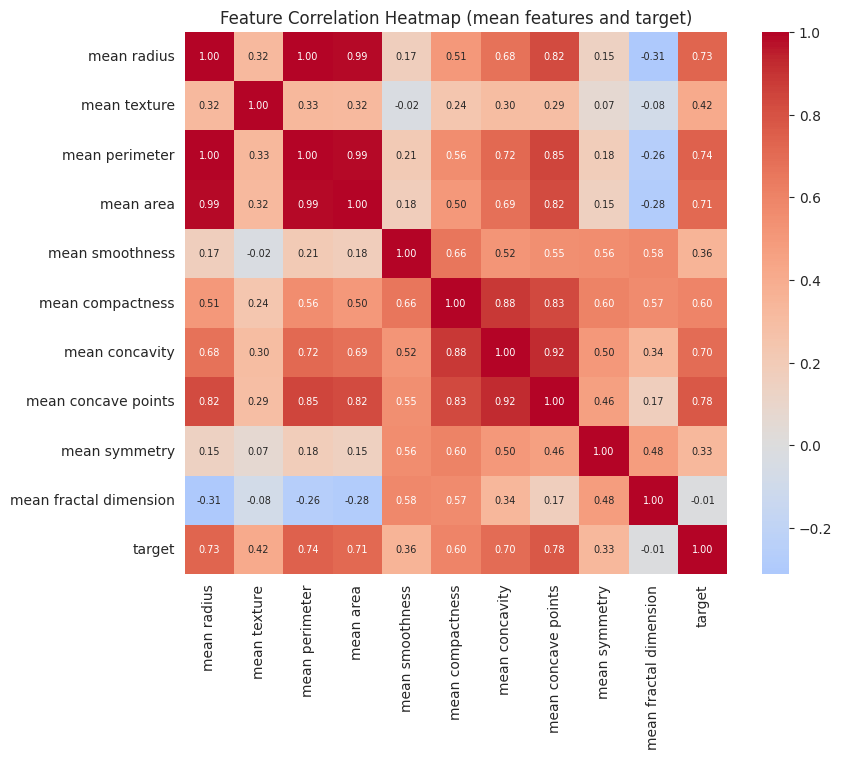

In [6]:
plt.figure(figsize=(9, 7.5))
corr = df[feature_names[:10] + ["target"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", annot_kws={"size": 7}, cmap="coolwarm", center=0, square=True)
plt.title("Feature Correlation Heatmap (mean features and target)")
plt.tight_layout()
plt.savefig("figures/fig_02_correlation_heatmap.png", dpi=110, bbox_inches="tight")
plt.show()

In [7]:
c = df[feature_names].corr().abs()
pairs = c.where(np.triu(np.ones(c.shape, dtype=bool), k=1)).stack().dropna().sort_values(ascending=False)
print("Feature pairs with |r| > 0.95:", int((pairs > 0.95).sum()), "of", len(pairs))
print(pairs.head(6).round(3))
tcorr = df[feature_names + ["target"]].corr()["target"].drop("target").sort_values(ascending=False)
print("\nStrongest correlations with malignancy:\n", tcorr.head(5).round(3))
print("\nWeakest correlations with malignancy:\n", tcorr.abs().sort_values().head(3).round(3))

Feature pairs with |r| > 0.95: 15 of 435
mean radius      mean perimeter     0.998
worst radius     worst perimeter    0.994
mean radius      mean area          0.987
mean perimeter   mean area          0.987
worst radius     worst area         0.984
worst perimeter  worst area         0.978
dtype: float64

Strongest correlations with malignancy:
 worst concave points    0.794
worst perimeter         0.783
mean concave points     0.777
worst radius            0.776
mean perimeter          0.743
Name: target, dtype: float64

Weakest correlations with malignancy:
 symmetry error            0.007
texture error             0.008
mean fractal dimension    0.013
Name: target, dtype: float64


**Inference:** The size features are almost duplicates of each other: 15 of the 435 feature pairs have an
absolute correlation above 0.95, the highest being mean radius with mean perimeter (0.998),
worst radius with worst perimeter (0.994) and mean radius with mean area (0.987). The
features most strongly related to malignancy are worst concave points (0.794), worst
perimeter (0.783), mean concave points (0.777), worst radius (0.776) and mean perimeter
(0.743), while symmetry error (0.007), texture error (0.008) and mean fractal dimension
(0.013) are essentially unrelated to the diagnosis. The redundancy does not harm tree-based
accuracy, but it means that feature importance will be shared among correlated features.

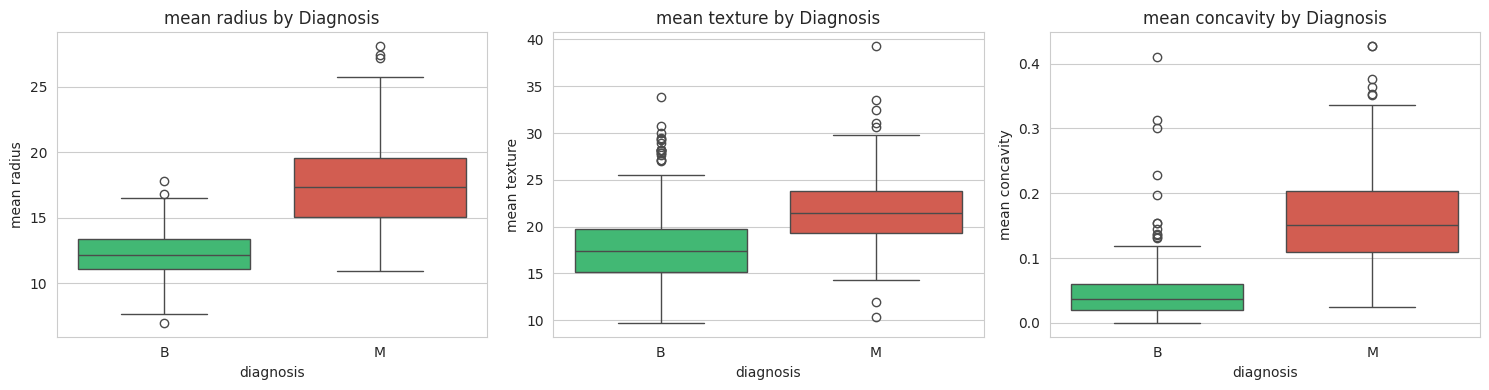

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, feat in zip(axes, ["mean radius", "mean texture", "mean concavity"]):
    sns.boxplot(data=df, x="diagnosis", y=feat, order=["B", "M"], ax=ax, palette=["#2ecc71", "#e74c3c"])
    ax.set_title(f"{feat} by Diagnosis")
plt.tight_layout()
plt.savefig("figures/fig_03_feature_boxplots.png", dpi=110, bbox_inches="tight")
plt.show()

**Inference:** Malignant tumours have a higher median mean radius (17.3 against 12.2) and a much higher
median mean concavity (0.151 against 0.037). For these two features the interquartile ranges
of the classes barely overlap (radius 15.1-19.6 against 11.1-13.4; concavity 0.110-0.203
against 0.020-0.060). Mean texture separates the classes less well (medians 21.5 and 17.4
with overlapping ranges). Radius and concavity are therefore expected to be good split
candidates.

## Step 3: Train-Test Split (80-20)

In [9]:
X = df[feature_names]
y = df["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print("Train shape:", X_train.shape, "| Test shape:", X_test.shape)
print("Malignant fraction  train: %.3f  test: %.3f" % (y_train.mean(), y_test.mean()))
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Train shape: (455, 30) | Test shape: (114, 30)
Malignant fraction  train: 0.374  test: 0.368


**Inference:** The stratified 80/20 split gives 455 training and 114 test patients (72 benign and 42
malignant in the test set), with malignant fractions of 0.374 and 0.368. All searches share
the same stratified 5-fold splits of the training set, so the Decision Tree and Random
Forest are compared on identical folds. With only 114 test patients, one patient changes
test accuracy by 0.9 percentage points, which should be kept in mind for every test-set
comparison below.

# Decision Tree

## Step 4: Baseline Decision Tree

In [10]:
dt_baseline = DecisionTreeClassifier(random_state=RANDOM_STATE).fit(X_train, y_train)
train_acc = accuracy_score(y_train, dt_baseline.predict(X_train))
test_acc = accuracy_score(y_test, dt_baseline.predict(X_test))
print(f"Baseline Decision Tree: train accuracy {train_acc:.4f} | test accuracy {test_acc:.4f}")
print(f"Tree depth: {dt_baseline.get_depth()} | Leaves: {dt_baseline.get_n_leaves()}")

Baseline Decision Tree: train accuracy 1.0000 | test accuracy 0.9298
Tree depth: 8 | Leaves: 24


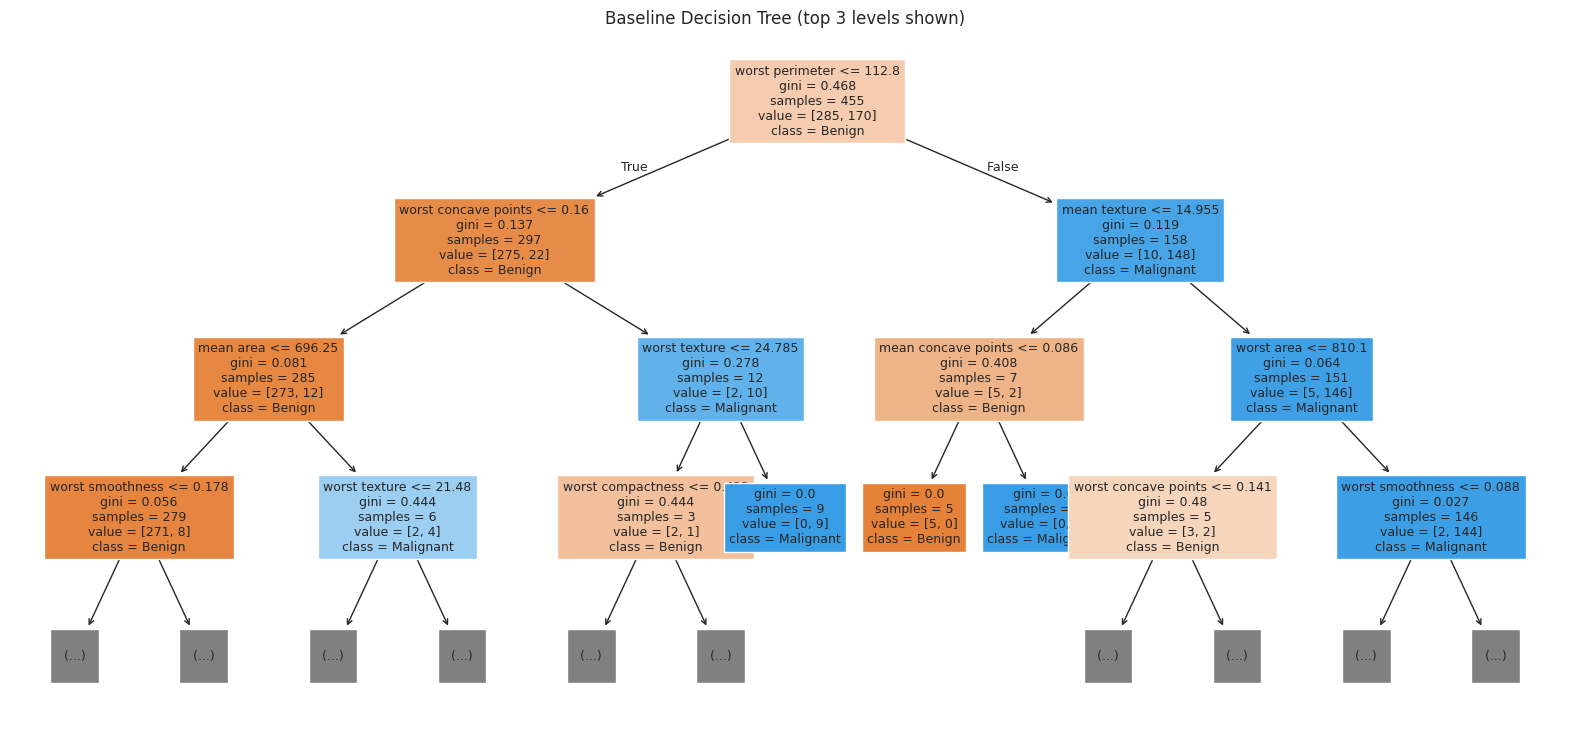

In [11]:
plt.figure(figsize=(20, 9))
plot_tree(dt_baseline, max_depth=3, feature_names=feature_names, class_names=["Benign", "Malignant"],
          filled=True, fontsize=9, proportion=False)
plt.title("Baseline Decision Tree (top 3 levels shown)")
plt.savefig("figures/fig_04_baseline_tree.png", dpi=110, bbox_inches="tight")
plt.show()

**Inference:** The unrestricted tree grows to depth 8 with 24 leaves, classifies every training patient
correctly (accuracy 1.000) and reaches 0.930 on the test set. A training accuracy of exactly
100% together with a lower test accuracy shows that it has memorised the training set,
including its noise.

## Effect of Tree Depth on Overfitting

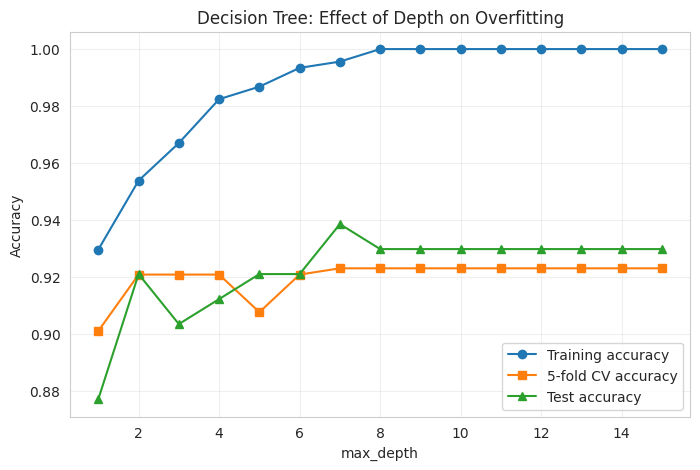

In [12]:
depths = list(range(1, 16))
tr, cvs, te = [], [], []
for d in depths:
    m = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE).fit(X_train, y_train)
    tr.append(accuracy_score(y_train, m.predict(X_train)))
    te.append(accuracy_score(y_test, m.predict(X_test)))
    cvs.append(cross_val_score(DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE), X_train, y_train, cv=cv).mean())
plt.figure(figsize=(8, 5))
plt.plot(depths, tr, marker="o", label="Training accuracy")
plt.plot(depths, cvs, marker="s", label="5-fold CV accuracy")
plt.plot(depths, te, marker="^", label="Test accuracy")
plt.xlabel("max_depth"); plt.ylabel("Accuracy")
plt.title("Decision Tree: Effect of Depth on Overfitting")
plt.legend(); plt.grid(True, alpha=0.3)
plt.savefig("figures/fig_05_depth_curve.png", dpi=110, bbox_inches="tight")
plt.show()

In [13]:
dd = pd.DataFrame({"max_depth": depths, "train": np.round(tr, 4), "cv": np.round(cvs, 4), "test": np.round(te, 4)})
print(dd.to_string(index=False))
print("Depth with best CV accuracy:", depths[int(np.argmax(cvs))])

 max_depth  train     cv   test
         1 0.9297 0.9011 0.8772
         2 0.9538 0.9209 0.9211
         3 0.9670 0.9209 0.9035
         4 0.9824 0.9209 0.9123
         5 0.9868 0.9077 0.9211
         6 0.9934 0.9209 0.9211
         7 0.9956 0.9231 0.9386
         8 1.0000 0.9231 0.9298
         9 1.0000 0.9231 0.9298
        10 1.0000 0.9231 0.9298
        11 1.0000 0.9231 0.9298
        12 1.0000 0.9231 0.9298
        13 1.0000 0.9231 0.9298
        14 1.0000 0.9231 0.9298
        15 1.0000 0.9231 0.9298
Depth with best CV accuracy: 7


**Inference:** Training accuracy rises from 0.930 for a single split to 1.000 at depth 8, which is the
depth of the fully grown tree, so the curves are flat beyond it. Cross-validation accuracy
is lowest for the stump (0.901), reaches about 0.921 at depth 2 and stays at 0.921 to 0.923
for all deeper trees. The cross-validation accuracy therefore does not fall as the tree
grows deeper; instead the gap between training and cross-validation accuracy widens from
0.033 at depth 2 to 0.077 at depth 8, so the extra depth only improves the fit to the
training data. A depth-1 stump underfits (test accuracy 0.877), and the test accuracy of
deeper trees fluctuates between 0.904 and 0.939 without a clear trend, which is typical for
a 114-patient test set.

## Steps 5-7: Hyperparameter Search with 5-Fold CV and Best Tree



Search space for the Decision Tree: criterion in {gini, entropy}, max_depth in {3, 5, 7, 10,
None}, min_samples_split in {2, 5, 10} and min_samples_leaf in {1, 2, 4}, i.e. 90
combinations, each evaluated with stratified 5-fold cross-validation (450 fits). Accuracy
and F1-score are recorded for every combination and the best average CV accuracy selects the
model.

In [14]:
dt_param_grid = {"criterion": ["gini", "entropy"], "max_depth": [3, 5, 7, 10, None],
                 "min_samples_split": [2, 5, 10], "min_samples_leaf": [1, 2, 4]}
t0 = time.time()
dt_grid = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE), param_grid=dt_param_grid, cv=cv,
                       scoring={"accuracy": "accuracy", "f1": "f1"}, refit="accuracy", n_jobs=1)
dt_grid.fit(X_train, y_train)
print("Total hyperparameter combinations evaluated:", len(dt_grid.cv_results_["params"]))
print("Search time: %.1fs" % (time.time() - t0))
print("Best Decision Tree params:", dt_grid.best_params_)
print(f"Best average CV accuracy: {dt_grid.best_score_:.4f}")
dt_results = pd.DataFrame(dt_grid.cv_results_)
dt_results["Avg CV Accuracy (%)"] = (dt_results["mean_test_accuracy"] * 100).round(2)
dt_results["Avg CV F1 Score"] = dt_results["mean_test_f1"].round(4)
dt_results["Criterion"] = dt_results["param_criterion"]
dt_results["Max Depth"] = dt_results["param_max_depth"].astype(str).replace({"nan": "None"})
dt_summary = (dt_results.sort_values("mean_test_accuracy", ascending=False)
              .groupby(["Criterion", "Max Depth"], dropna=False).first().reset_index()
              [["Criterion", "Max Depth", "Avg CV Accuracy (%)", "Avg CV F1 Score"]]
              .sort_values("Avg CV Accuracy (%)", ascending=False).reset_index(drop=True))

Total hyperparameter combinations evaluated: 90
Search time: 5.5s
Best Decision Tree params: {'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 2, 'min_samples_split': 10}
Best average CV accuracy: 0.9363


In [15]:
dt_summary
dt_summary

,Criterion,Max Depth,Avg CV Accuracy (%),Avg CV F1 Score
0,entropy,5,93.63,0.9121
1,entropy,10,93.41,0.9094
2,entropy,NaN,93.41,0.9094
3,entropy,7,93.41,0.9094
4,gini,NaN,92.97,0.9039
5,gini,10,92.97,0.9039
6,gini,7,92.97,0.9039
7,gini,3,92.75,0.8990
8,entropy,3,92.53,0.8941
9,gini,5,92.53,0.8971


| Criterion | Max Depth | Avg CV Accuracy (%) | Avg CV F1 Score |
|---|---|---|---|
| entropy | 5 | 93.6300 | 0.9121 |
| entropy | 10 | 93.4100 | 0.9094 |
| entropy | None | 93.4100 | 0.9094 |
| entropy | 7 | 93.4100 | 0.9094 |
| gini | None | 92.9700 | 0.9039 |
| gini | 10 | 92.9700 | 0.9039 |
| gini | 7 | 92.9700 | 0.9039 |
| gini | 3 | 92.7500 | 0.8990 |
| entropy | 3 | 92.5300 | 0.8941 |
| gini | 5 | 92.5300 | 0.8971 |


**Inference:** The 90 combinations (450 fits) were evaluated in a few seconds. The best Decision Tree uses
the entropy criterion, max_depth 5, min_samples_leaf 2 and min_samples_split 10, with an
average CV accuracy of 0.9363. In the summary table entropy at depth 5 leads (93.63%) and
the best gini settings reach 92.97%. The rows for max_depth 7, 10 and None are identical
because the tree stops growing at depth 8 anyway. Across the whole table the differences are
about one percentage point, which is only about 4 patients out of 455.

In [16]:
dt_best = dt_grid.best_estimator_
dt_train_acc = accuracy_score(y_train, dt_best.predict(X_train))
dt_test_acc = accuracy_score(y_test, dt_best.predict(X_test))
print("Tuned Decision Tree params:", dt_grid.best_params_)
print(f"Train accuracy: {dt_train_acc:.4f} | Test accuracy: {dt_test_acc:.4f}")
print(f"Tree depth: {dt_best.get_depth()} | Leaves: {dt_best.get_n_leaves()}")

Tuned Decision Tree params: {'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 2, 'min_samples_split': 10}
Train accuracy: 0.9758 | Test accuracy: 0.9649
Tree depth: 5 | Leaves: 12


**Inference:** Restricting the tree to depth 5 and 12 leaves lowers training accuracy from 1.000 to 0.976
but raises test accuracy from 0.930 to 0.965, a gain of 4 patients out of 114. This is the
expected effect of regularising a high-variance model, but it comes from a single small test
set and should not be over-interpreted.

# Random Forest

## Step 8: Baseline Random Forest

In [17]:
rf_baseline = RandomForestClassifier(random_state=RANDOM_STATE).fit(X_train, y_train)
rf_train_acc = accuracy_score(y_train, rf_baseline.predict(X_train))
rf_test_acc = accuracy_score(y_test, rf_baseline.predict(X_test))
print(f"Baseline Random Forest (100 trees): train accuracy {rf_train_acc:.4f} | test accuracy {rf_test_acc:.4f}")

Baseline Random Forest (100 trees): train accuracy 1.0000 | test accuracy 0.9737


**Inference:** A default Random Forest with 100 trees already has 0.974 test accuracy (3 errors out of
114), higher than both the baseline and the tuned Decision Tree, although its training
accuracy is also 1.000. Unlike a single tree, a forest can fit the training data perfectly
and still generalise well, because the trees' individual errors average out.

## Steps 9-10: Hyperparameter Search with 5-Fold CV and Best Forest



Search space for the Random Forest: n_estimators in {50, 100, 200}, max_depth in {5, 10,
None}, max_features in {sqrt, log2} and bootstrap in {True, False}, i.e. 36 combinations
evaluated with the same stratified 5-fold splits (180 fits).

In [18]:
rf_param_grid = {"n_estimators": [50, 100, 200], "max_depth": [5, 10, None],
                 "max_features": ["sqrt", "log2"], "bootstrap": [True, False]}
t0 = time.time()
rf_grid = GridSearchCV(RandomForestClassifier(random_state=RANDOM_STATE), param_grid=rf_param_grid, cv=cv,
                       scoring={"accuracy": "accuracy", "f1": "f1"}, refit="accuracy", n_jobs=1)
rf_grid.fit(X_train, y_train)
print("Total hyperparameter combinations evaluated:", len(rf_grid.cv_results_["params"]))
print("Search time: %.1fs" % (time.time() - t0))
print("Best Random Forest params:", rf_grid.best_params_)
print(f"Best average CV accuracy: {rf_grid.best_score_:.4f}")
rf_results = pd.DataFrame(rf_grid.cv_results_)
rf_results["Avg CV Accuracy (%)"] = (rf_results["mean_test_accuracy"] * 100).round(2)
rf_results["Avg CV F1 Score"] = rf_results["mean_test_f1"].round(4)
rf_results["n_estimators"] = rf_results["param_n_estimators"]
rf_results["Max Depth"] = rf_results["param_max_depth"].astype(str).replace({"nan": "None"})
rf_results["Max Features"] = rf_results["param_max_features"]
rf_summary = (rf_results.sort_values("mean_test_accuracy", ascending=False)
              .groupby(["n_estimators", "Max Depth", "Max Features"], dropna=False).first().reset_index()
              [["n_estimators", "Max Depth", "Max Features", "Avg CV Accuracy (%)", "Avg CV F1 Score"]]
              .sort_values("Avg CV Accuracy (%)", ascending=False).reset_index(drop=True))

Total hyperparameter combinations evaluated: 36
Search time: 41.2s
Best Random Forest params: {'bootstrap': False, 'max_depth': 5, 'max_features': 'sqrt', 'n_estimators': 200}
Best average CV accuracy: 0.9714


In [19]:
rf_summary
rf_summary

,n_estimators,Max Depth,Max Features,Avg CV Accuracy (%),Avg CV F1 Score
0,50,10,sqrt,97.14,0.9617
1,200,5,sqrt,97.14,0.9608
2,200,10,sqrt,97.14,0.9615
3,200,NaN,sqrt,97.14,0.9615
4,50,10,log2,96.92,0.9584
5,50,NaN,sqrt,96.92,0.9589
6,100,5,sqrt,96.92,0.9580
7,50,NaN,log2,96.92,0.9584
8,100,10,log2,96.92,0.9585
9,100,5,log2,96.70,0.9550


| n_estimators | Max Depth | Max Features | Avg CV Accuracy (%) | Avg CV F1 Score |
|---|---|---|---|---|
| 50 | 10 | sqrt | 97.1400 | 0.9617 |
| 200 | 5 | sqrt | 97.1400 | 0.9608 |
| 200 | 10 | sqrt | 97.1400 | 0.9615 |
| 200 | None | sqrt | 97.1400 | 0.9615 |
| 50 | 10 | log2 | 96.9200 | 0.9584 |
| 50 | None | sqrt | 96.9200 | 0.9589 |
| 100 | 5 | sqrt | 96.9200 | 0.9580 |
| 50 | None | log2 | 96.9200 | 0.9584 |
| 100 | 10 | log2 | 96.9200 | 0.9585 |
| 100 | 5 | log2 | 96.7000 | 0.9550 |
| 200 | 10 | log2 | 96.7000 | 0.9557 |
| 100 | None | log2 | 96.7000 | 0.9556 |
| 50 | 5 | sqrt | 96.4800 | 0.9520 |
| 100 | 10 | sqrt | 96.4800 | 0.9519 |
| 200 | None | log2 | 96.4800 | 0.9524 |
| 100 | None | sqrt | 96.4800 | 0.9519 |
| 50 | 5 | log2 | 96.2600 | 0.9485 |
| 200 | 5 | log2 | 96.2600 | 0.9490 |


**Inference:** The 36 combinations (180 fits) took under a minute. The best forest uses 200 trees,
max_depth 5, max_features sqrt and bootstrap False, with a CV accuracy of 0.9714. Four
configurations tie at 97.14%, and every configuration lies between 96.3% and 97.1%, so the
forest is far less sensitive to its hyperparameters than a single tree (92.5% to 93.6%).

In [20]:
rf_best = rf_grid.best_estimator_
rf_best_train_acc = accuracy_score(y_train, rf_best.predict(X_train))
rf_best_test_acc = accuracy_score(y_test, rf_best.predict(X_test))
print("Tuned Random Forest params:", rf_grid.best_params_)
print(f"Train accuracy: {rf_best_train_acc:.4f} | Test accuracy: {rf_best_test_acc:.4f}")

Tuned Random Forest params: {'bootstrap': False, 'max_depth': 5, 'max_features': 'sqrt', 'n_estimators': 200}
Train accuracy: 0.9912 | Test accuracy: 0.9649


**Inference:** The tuned forest has training accuracy 0.991 and test accuracy 0.965 (4 errors). This is
slightly below the default forest (0.974, 3 errors), although its CV accuracy is higher. The
one-patient difference is within noise, so on this test set tuning gave no measurable
benefit over the default settings.

## Which Hyperparameter Matters Most?

In [21]:
rows = []
for name, res, params in [("Decision Tree", dt_results, ["criterion", "max_depth", "min_samples_split", "min_samples_leaf"]),
                          ("Random Forest", rf_results, ["n_estimators", "max_depth", "max_features", "bootstrap"])]:
    for p in params:
        g = res.groupby(res["param_" + p].astype(str))["mean_test_accuracy"].mean()
        rows.append({"Model": name, "Hyperparameter": p, "Worst value (mean CV acc.)": g.min(),
                     "Best value (mean CV acc.)": g.max(), "Spread": g.max() - g.min()})
impact = pd.DataFrame(rows)

In [22]:
impact
impact

,Model,Hyperparameter,Worst value (mean CV acc.),Best value (mean CV acc.),Spread
0,Decision Tree,criterion,0.920781,0.925958,0.005177
1,Decision Tree,max_depth,0.922100,0.923932,0.001832
2,Decision Tree,min_samples_split,0.923150,0.923590,0.000440
3,Decision Tree,min_samples_leaf,0.920366,0.926447,0.006081
4,Random Forest,n_estimators,0.964103,0.965385,0.001282
5,Random Forest,max_depth,0.963553,0.965568,0.002015
6,Random Forest,max_features,0.964347,0.965201,0.000855
7,Random Forest,bootstrap,0.962271,0.967277,0.005006


| Model | Hyperparameter | Worst value (mean CV acc.) | Best value (mean CV acc.) | Spread |
|---|---|---|---|---|
| Decision Tree | criterion | 0.9208 | 0.9260 | 0.0052 |
| Decision Tree | max_depth | 0.9221 | 0.9239 | 0.0018 |
| Decision Tree | min_samples_split | 0.9232 | 0.9236 | 0.0004 |
| Decision Tree | min_samples_leaf | 0.9204 | 0.9264 | 0.0061 |
| Random Forest | n_estimators | 0.9641 | 0.9654 | 0.0013 |
| Random Forest | max_depth | 0.9636 | 0.9656 | 0.0020 |
| Random Forest | max_features | 0.9643 | 0.9652 | 0.0009 |
| Random Forest | bootstrap | 0.9623 | 0.9673 | 0.0050 |


**Inference:** For the Decision Tree, min_samples_leaf (spread 0.0061) and the criterion (0.0052) matter
most, followed by max_depth (0.0018) and min_samples_split (0.0004). For the Random Forest
the largest effect is bootstrap (0.0050, better with False: 0.9673 against 0.9623), followed
by max_depth (0.0020), n_estimators (0.0013) and max_features (0.0009). Every individual
hyperparameter changes the mean CV accuracy by at most 0.6 percentage points, whereas
changing the model family from one tree to a forest raises it by 3.5 points (0.9363 to
0.9714).

# Model Comparison

## Step 11: Evaluation Metrics

In [23]:
def evaluate(model, X_te, y_te, name):
    pred = model.predict(X_te)
    return {"Model": name, "Accuracy": accuracy_score(y_te, pred), "Precision": precision_score(y_te, pred),
            "Recall": recall_score(y_te, pred), "F1-score": f1_score(y_te, pred),
            "ROC-AUC": auc(*roc_curve(y_te, model.predict_proba(X_te)[:, 1])[:2])}
metrics_df = pd.DataFrame([evaluate(dt_best, X_test, y_test, "Decision Tree (tuned)"),
                           evaluate(rf_best, X_test, y_test, "Random Forest (tuned)")])

In [24]:
metrics_df
metrics_df

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Decision Tree (tuned),0.964912,1.0,0.904762,0.95,0.974372
1,Random Forest (tuned),0.964912,1.0,0.904762,0.95,0.993717


| Model | Accuracy | Precision | Recall | F1-score | ROC-AUC |
|---|---|---|---|---|---|
| Decision Tree (tuned) | 0.9649 | 1.0000 | 0.9048 | 0.9500 | 0.9744 |
| Random Forest (tuned) | 0.9649 | 1.0000 | 0.9048 | 0.9500 | 0.9937 |


**Inference:** Both tuned models obtain exactly the same hard-label scores: accuracy 0.9649, precision
1.000, recall 0.905 and F1-score 0.950. They differ in ROC-AUC, which is 0.974 for the
Decision Tree and 0.994 for the Random Forest. The forest therefore ranks patients by risk
better, even though the two models make the same number of errors at the default 0.5
threshold.

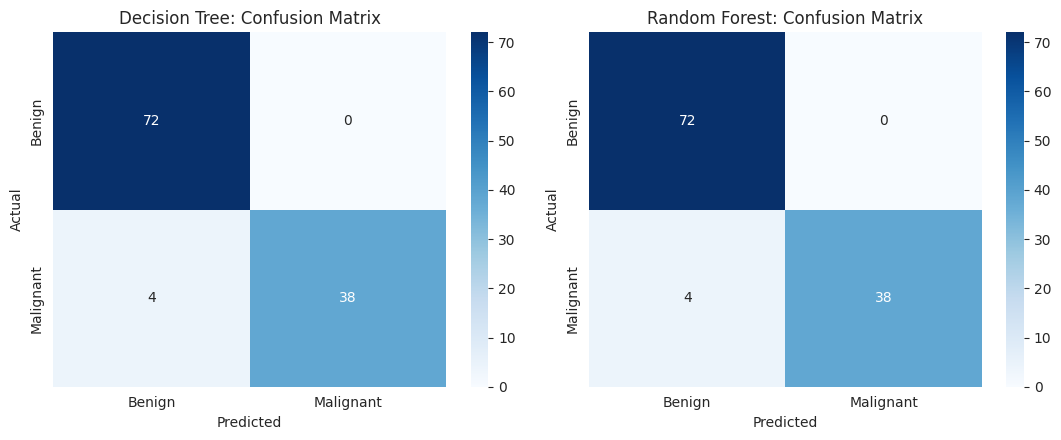

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, model, name in zip(axes, [dt_best, rf_best], ["Decision Tree", "Random Forest"]):
    cm = confusion_matrix(y_test, model.predict(X_test), labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax, xticklabels=["Benign", "Malignant"],
                yticklabels=["Benign", "Malignant"])
    ax.set_title(f"{name}: Confusion Matrix")
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout()
plt.savefig("figures/fig_06_confusion_matrices.png", dpi=110, bbox_inches="tight")
plt.show()

**Inference:** Both models make no false alarms (72 benign patients all correct) and detect 38 of the 42
malignant patients, missing 4. Missing a malignant tumour is the more serious error in this
application, so in practice the threshold should be lowered to raise recall. The forest's
averaged probabilities allow this to be done smoothly, whereas a 12-leaf tree only produces
a handful of distinct probability values.

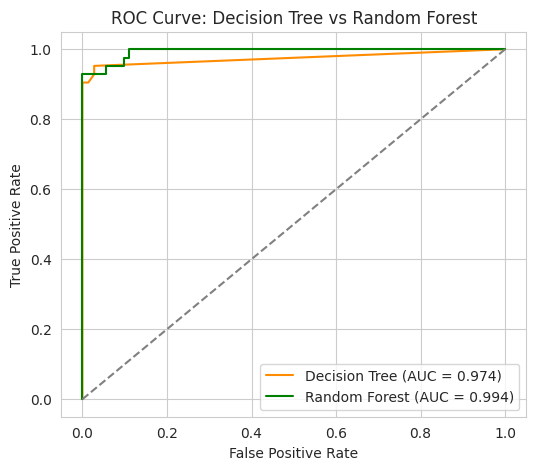

In [26]:
plt.figure(figsize=(6, 5))
for model, name, color in [(dt_best, "Decision Tree", "darkorange"), (rf_best, "Random Forest", "green")]:
    fpr, tpr, _ = roc_curve(y_test, model.predict_proba(X_test)[:, 1])
    plt.plot(fpr, tpr, color=color, label=f"{name} (AUC = {auc(fpr, tpr):.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curve: Decision Tree vs Random Forest")
plt.legend(loc="lower right")
plt.savefig("figures/fig_07_roc.png", dpi=110, bbox_inches="tight")
plt.show()

**Inference:** The Random Forest curve lies above the Decision Tree curve over most of the range and
reaches a true positive rate close to 1 at a very low false positive rate (AUC 0.994 against
0.974). This is the clearest difference between the two models on the test set.

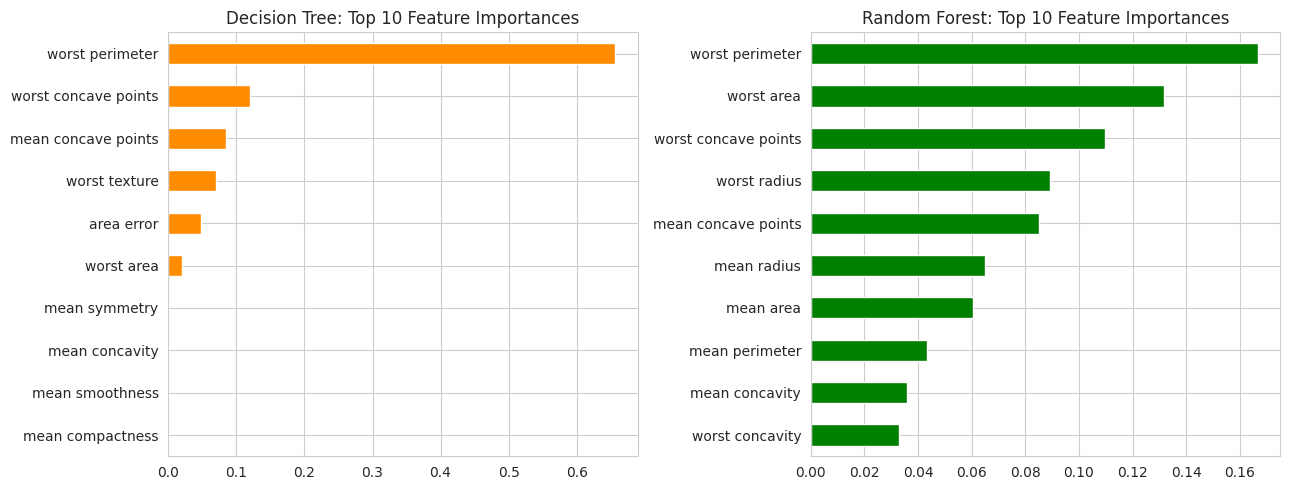

In [27]:
dt_imp = pd.Series(dt_best.feature_importances_, index=feature_names).sort_values(ascending=False).head(10)
rf_imp = pd.Series(rf_best.feature_importances_, index=feature_names).sort_values(ascending=False).head(10)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
dt_imp.sort_values().plot.barh(ax=axes[0], color="darkorange")
axes[0].set_title("Decision Tree: Top 10 Feature Importances")
rf_imp.sort_values().plot.barh(ax=axes[1], color="green")
axes[1].set_title("Random Forest: Top 10 Feature Importances")
plt.tight_layout()
plt.savefig("figures/fig_08_feature_importance.png", dpi=110, bbox_inches="tight")
plt.show()

In [28]:
print("Decision Tree top 5:\n", dt_imp.head(5).round(3))
print("\nRandom Forest top 5:\n", rf_imp.head(5).round(3))
print("\nDecision Tree features with non-zero importance:", int((dt_best.feature_importances_ > 0).sum()), "of 30")

Decision Tree top 5:
 worst perimeter         0.657
worst concave points    0.120
mean concave points     0.084
worst texture           0.070
area error              0.048
dtype: float64

Random Forest top 5:
 worst perimeter         0.167
worst area              0.132
worst concave points    0.110
worst radius            0.089
mean concave points     0.085
dtype: float64

Decision Tree features with non-zero importance: 6 of 30


**Inference:** The tuned Decision Tree uses only 6 of the 30 features and relies on worst perimeter for
65.7% of its importance, followed by worst concave points (12.0%), mean concave points
(8.4%), worst texture (7.0%) and area error (4.8%). The forest spreads its importance over
the correlated size features: worst perimeter (16.7%), worst area (13.2%), worst concave
points (11.0%), worst radius (8.9%) and mean concave points (8.5%). A single tree picks one
of the near-duplicate size measures, while different trees in the forest pick different
ones. Concave points features are important in both models, in agreement with the
correlation analysis.

## Step 12: 5-Fold Cross-Validation Comparison

In [29]:
dt_fold_scores = cross_val_score(dt_best, X_train, y_train, cv=cv, scoring="accuracy")
rf_fold_scores = cross_val_score(rf_best, X_train, y_train, cv=cv, scoring="accuracy")
fold_comparison = pd.DataFrame({"Model": ["Decision Tree", "Random Forest"]})
for i in range(5):
    fold_comparison[f"Fold {i+1}"] = [dt_fold_scores[i], rf_fold_scores[i]]
fold_comparison["Average"] = [dt_fold_scores.mean(), rf_fold_scores.mean()]
fold_comparison["Std Dev"] = [dt_fold_scores.std(ddof=1), rf_fold_scores.std(ddof=1)]

In [30]:
fold_comparison
fold_comparison

,Model,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Average,Std Dev
0,Decision Tree,0.901099,0.956044,0.912088,0.956044,0.956044,0.936264,0.027362
1,Random Forest,0.956044,1.000000,0.945055,0.967033,0.989011,0.971429,0.022787


| Model | Fold 1 | Fold 2 | Fold 3 | Fold 4 | Fold 5 | Average | Std Dev |
|---|---|---|---|---|---|---|---|
| Decision Tree | 0.9011 | 0.9560 | 0.9121 | 0.9560 | 0.9560 | 0.9363 | 0.0274 |
| Random Forest | 0.9560 | 1.0000 | 0.9451 | 0.9670 | 0.9890 | 0.9714 | 0.0228 |

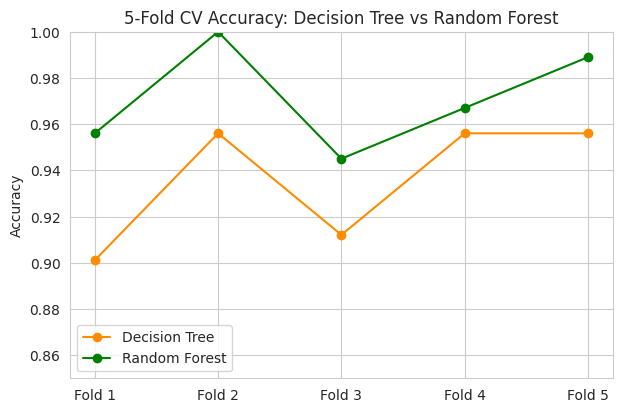

In [31]:
plt.figure(figsize=(7, 4.5))
folds = [f"Fold {i+1}" for i in range(5)]
plt.plot(folds, dt_fold_scores, marker="o", label="Decision Tree", color="darkorange")
plt.plot(folds, rf_fold_scores, marker="o", label="Random Forest", color="green")
plt.ylabel("Accuracy"); plt.title("5-Fold CV Accuracy: Decision Tree vs Random Forest")
plt.legend(); plt.ylim(0.85, 1.0)
plt.savefig("figures/fig_09_cv_folds.png", dpi=110, bbox_inches="tight")
plt.show()

**Inference:** The Random Forest averages 0.9714 (standard deviation 0.0228) and the Decision Tree 0.9363
(0.0274), and the forest is better in every one of the five folds (0.956 against 0.901,
1.000 against 0.956, 0.945 against 0.912, 0.967 against 0.956 and 0.989 against 0.956).
These scores are measured on the same training data and folds that were used for tuning, so
they are slightly optimistic, but the same folds are used for both models.

## Does the Ensemble Always Win? Repeated Random Splits



To check whether the Random Forest is better on every split, or only on this particular one,
both tuned configurations were refitted on 30 different stratified 80/20 splits.

In [32]:
res = []
for seed in range(30):
    Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.2, stratify=y, random_state=seed)
    a = DecisionTreeClassifier(**dt_grid.best_params_, random_state=seed).fit(Xa, ya)
    b = RandomForestClassifier(**rf_grid.best_params_, random_state=seed).fit(Xa, ya)
    res.append((accuracy_score(yb, a.predict(Xb)), accuracy_score(yb, b.predict(Xb))))
res = np.array(res)
rep = pd.DataFrame({"Model": ["Decision Tree", "Random Forest"], "Mean accuracy": res.mean(axis=0),
                    "Std dev": res.std(axis=0, ddof=1), "Min": res.min(axis=0), "Max": res.max(axis=0)})
wins, ties, losses = int((res[:, 1] > res[:, 0]).sum()), int((res[:, 1] == res[:, 0]).sum()), int((res[:, 1] < res[:, 0]).sum())
print(f"Random Forest vs Decision Tree over 30 splits: wins {wins}, ties {ties}, losses {losses}")

Random Forest vs Decision Tree over 30 splits: wins 24, ties 3, losses 3


In [33]:
rep
rep

,Model,Mean accuracy,Std dev,Min,Max
0,Decision Tree,0.935673,0.020127,0.885965,0.964912
1,Random Forest,0.958480,0.018847,0.912281,0.991228


| Model | Mean accuracy | Std dev | Min | Max |
|---|---|---|---|---|
| Decision Tree | 0.9357 | 0.0201 | 0.8860 | 0.9649 |
| Random Forest | 0.9585 | 0.0188 | 0.9123 | 0.9912 |


**Inference:** Over 30 different stratified splits the tuned forest has a mean test accuracy of 0.9585
(standard deviation 0.0188) against 0.9357 (0.0201) for the tuned tree. It wins on 24
splits, ties on 3 and loses on 3. The hyperparameters were chosen on the training part of
the original split, which overlaps the test parts of the other splits, so the absolute
accuracies are somewhat optimistic for both models, but the comparison is still informative.

# Observation Questions



**1. How does tree depth affect overfitting in Decision Trees?** Depth controls how closely a tree can fit the training data. An unrestricted tree reaches 100% training accuracy at depth 8 but only 0.930 on the test set. The gap between training and cross-validation accuracy widens from 0.033 at depth 2 to 0.077 at depth 8, while cross-validation accuracy stays at about 0.92, so the additional depth only memorises training noise. A depth-1 stump underfits (training accuracy 0.930, test accuracy 0.877). Moderate depth (about 3 to 5) together with a minimum leaf size gave the best balance: the tuned depth-5 tree has lower training accuracy (0.976) but higher test accuracy (0.965).

**2. Which hyperparameter had the greatest impact on performance?** Among single hyperparameters the largest effects were min_samples_leaf (0.6 percentage points) and the criterion (0.5 points) for the Decision Tree, and bootstrap (0.5 points) for the Random Forest, with entropy, a minimum leaf size above 1 and bootstrap False performing best. All of them are small, and each corresponds to only two to three patients out of 455. The choice between a single tree and a forest changed cross-validation accuracy by 3.5 points, so the model family had a much larger effect than any hyperparameter.

**3. How does Random Forest improve generalisation?** A Random Forest trains each tree on a different sample (bagging) and lets each split see only a random subset of features, so the individual trees make partly independent errors that average out in the vote. This reduces variance without raising bias much. In these results the forest gains 3.5 points of CV accuracy over the tuned tree (0.9714 against 0.9363), is better in all five folds, raises ROC-AUC from 0.974 to 0.994 and is much less sensitive to its hyperparameters (every configuration within 96.3% to 97.1%). Even the untuned forest reaches 0.974 on the test set despite a training accuracy of 1.000.

**4. Did ensemble learning always improve performance? Why or why not?** No. On this particular test split the tuned forest and the tuned tree are tied (both 0.9649, with the same four missed malignant cases), and the untuned forest (0.974) is one patient better than the tuned forest. Over 30 random splits the forest won 24 times, tied 3 times and lost 3 times, so its advantage is clear on average (2.3 percentage points) but not guaranteed. The reasons are that the dataset is small and clean with strongly informative features, so a regularised single tree already reaches about 96%, and that variance reduction helps least when variance is already low. The forest also costs more: 200 trees, a longer search (about 43 s against 6 s here) and no single tree that can be read as a set of rules.

# Conclusion



A Decision Tree and a Random Forest were tuned with 5-fold cross-validation on the WDBC
data. Limiting the depth of the tree (depth 5, entropy criterion) improved its test accuracy
from 0.930 to 0.965, and the Random Forest reached a CV accuracy of 0.971 against 0.936 for
the tree, was better in all five folds, had ROC-AUC 0.994 against 0.974 and won on 24 of 30
random splits. On the single held-out split both tuned models made the same four errors, all
missed malignant cases, so the advantage of the ensemble appears in cross-validation and in
ranking quality, not in this particular test accuracy. Hyperparameters mattered far less
than the choice between a single tree and an ensemble. For a diagnostic application the
Random Forest is preferable, with its decision threshold lowered to increase recall for
malignant tumours.

# References



[1] L. Breiman, J. H. Friedman, R. A. Olshen and C. J. Stone, Classification and Regression Trees. Wadsworth, 1984.

[2] L. Breiman, "Random forests," Machine Learning, vol. 45, no. 1, pp. 5-32, 2001.

[3] F. Pedregosa et al., "Scikit-learn: Machine learning in Python," Journal of Machine Learning Research, vol. 12, pp. 2825-2830, 2011.

[4] W. H. Wolberg, W. N. Street and O. L. Mangasarian, "Breast Cancer Wisconsin (Diagnostic)," UCI Machine Learning Repository, 1995. [Online]. Available: https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic

[5] Scikit-learn User Guide: Decision Trees and Ensemble Methods. [Online]. Available: https://scikit-learn.org/stable/modules/tree.html